# Assignment 4

In [26]:
# Import the necessary libraries
import matplotlib.pyplot as plt
import numpy as np
import time
import ipywidgets as widgets
from IPython.display import display

In [27]:
BOOK_PATH = "goblet_book.txt"

## Data Handler Class

In [28]:
class DataHandler:
    """
    Class for data management.

    Args:
        file_name: The name of the file to read.
    Attributes:
        data: The data read from the file.
        data_vector: A list of unique characters in the data.
        K: Dim. of the data (length of data_vector).
    """

    def __init__(self, file_name):

        # Load data:
        try:
            with open(file_name, "r", encoding="utf-8") as fid:
                self.data = fid.read()
        except FileNotFoundError:
            raise FileNotFoundError(f"Could not find file: {file_name}")
        
        # Store characters, length and dimension
        self.data_vector = list(set(self.data))
        self.K = len(self.data_vector)
        self.N = len(self.data)

        # Create fast lookup dictionaries
        self.char_to_ind_dict = {char: ind for ind, char in enumerate(self.data_vector)}
        self.ind_to_char_dict = {ind: char for ind, char in enumerate(self.data_vector)}

        # Prepare a rng (which will likely be updated by network later)
        self.rng = np.random.default_rng()
        
        # Print status
        print(f"DataHandler: Loaded file {file_name} with dimension {self.K} of length {self.N}.")

    def char_to_ind(self, char):
        """
        Convert a character to an index based on the dict. char_to_ind_dict.

        Args:
            char: The character to convert.
        Returns:
            The index of the character in the data vector.
        """
        return self.char_to_ind_dict[char]
    
    def sec_to_one_hot(self, sec):
        seq_len = len(sec)
        one_hot = np.zeros((self.K, seq_len))
        indices = [self.char_to_ind_dict[c] for c in sec]
        one_hot[indices, np.arange(seq_len)] = 1
        return one_hot

    def ind_to_char(self, ind):
        """
        Convert an index to a character based on the dict. ind_to_char_dict.

        Args:
            ind: The index to convert.
        Returns:
            The character corresponding to the index in the data vector.
        """
        return self.ind_to_char_dict[ind]
    
    def get_input_seq(self, e, seq_length):
        return self.data[e:e+seq_length]
    
    def get_target_seq(self, e, seq_length):
        return self.data[e+1 : e+seq_length+1]
    
    def get_target_indices(self, e, seq_length):
        raw_str = self.get_target_seq(e, seq_length)
        return np.array([self.char_to_ind_dict[c] for c in raw_str])
    
    # Note that the following two functions should be possible
    # to combine and make shorter...
    def get_input_seq_one_hot(self, e, seq_length):
        return self.sec_to_one_hot(self.get_input_seq(e, seq_length))
    
    def get_target_seq_one_hot(self, e, seq_length):
        return self.sec_to_one_hot(self.get_target_seq(e, seq_length))

    def get_random_char_one_hot(self):
        random_char = self.rng.choice(self.data_vector)
        return self.sec_to_one_hot(random_char)

We explore the data a bit before continuing...

In [29]:
data_handler = DataHandler(BOOK_PATH)
# print(f"data_vector: {data_handler.data_vector}")
# print(f"char_to_ind_dict: {data_handler.char_to_ind_dict}")
# print(f"ind_to_char_dict: {data_handler.ind_to_char_dict}")

DataHandler: Loaded file goblet_book.txt with dimension 80 of length 1107542.


## Neural Network Class

In [30]:
class Activation:
    @staticmethod
    def sigmoid(X):
        """
        Sigmoid activation function.

        Args:
            X: Input array of shape (d, N)
        Returns:
            Output array of shape (d, N)
        """
        return 1 / (1 + np.exp(-X))
    @staticmethod
    def sigmoid_derivative(**kwargs):
        """
        Sigmoid derivative function.
        
        Args:
            G: Incoming gradient of shape (d, N)
            Y: Input array of shape (d, N) holding layer output
        Returns:
            Output array of shape (d, N)
        """
        G = kwargs['G']
        Y = kwargs['Y']
        return G * Y * (1 - Y)
    @staticmethod
    def softmax(X, T=1.0):
        """
        Softmax activation function, optionally with temperature scaling.

        Args:
            X (np.ndarray): Input array of shape (K, N)
            T (float, optional): Temperature [0, 1].
        Returns:
            np.ndarray: Output array of shape (K, N)
        """
        if T is not None:
            if T < 0 or T > 1.0:
                raise ValueError("Softmax temperature must be in the range [0, 1].")
            if T == 0:
                # Potentially add protection against 0 division
                pass
        # Catch None case
        if T is None:
            T = 1.0
        # Apply temperature scaling (note that T=1.0 is same as no temperature)
        shifted_X = (X - np.max(X, axis=0, keepdims=True)) / T
        exp_Z = np.exp(shifted_X)
        return exp_Z / np.sum(exp_Z, axis=0, keepdims=True)
    @staticmethod
    def softmax_derivative(**kwargs):
        """
        Args:
            X: Input array (pre-activation scores)
            Y: One-hot-encoded labels
        Returns:
            P - Y (the proper gradient for cross-entropy + softmax)
        """
        X = kwargs['X']
        Y = kwargs['Y']
        P = Activation.softmax(X=X)
        return P - Y  # Return P - Y_labels directly
    
    @staticmethod
    def tahn(X):
        """
        Tanh activation function.

        Args:
            X: Input array of shape (d, N)
        Returns:
            Output array of shape (d, N)
        """
        return np.tanh(X)
    @staticmethod
    def tahn_derivative(**kwargs):
        """
        Tanh derivative function.

        Source: https://medium.com/@vikrampande783/derivative-of-sigmoid-and-tanh-ffdea6efb464

        Args:
            G: Incoming gradient of shape (d, N)
            Y: Input array of shape (d, N) holding layer output
        Returns:
            Output array of shape (d, N)
        """
        G = kwargs['G']
        Y = kwargs['Y']
        return G * (1 - Y**2)

In [31]:
class Layer:

    def __init__(self, net, lam, activation = None):
        self.prev_layer = None
        self.next_layer = None

        self.net = net
        self.lam = lam

        self.X = []
        self.Y = []
        self.Z = []

        self.G = None # Holds gradients to be passed to upper layer

        if activation == "softmax":
            self.activation_func = Activation.softmax
            self.activation_func_derivative = Activation.softmax_derivative
        elif activation == "tanh":
            self.activation_func = Activation.tahn
            self.activation_func_derivative = Activation.tahn_derivative
        elif activation == None:
            self.activation_func = None
            self.activation_func_derivative = None
        else:
            raise(f"Unsupported activation detected.")

    def update_params(self, eta):
        pass

    def clear(self):
        pass

    def get_X(self):
        return self.X[-1] if isinstance(self.X, list) else self.X
    def get_first_X(self):
        return self.X[0] if isinstance(self.X, list) else self.X
    
    def get_Y(self):
        return self.Y[-1] if isinstance(self.Y, list) else self.Y
    def get_first_Y(self):
        return self.Y[0] if isinstance(self.Y, list) else self.Y
    
    def get_Z(self):
        if len(self.Z) == 0:
            return None
        return self.Z[-1] if isinstance(self.Z, list) else self.Z

In [32]:
class FullyConnectedLayer(Layer):
    def __init__(self, net, d, m, activation, lam = 0.):
        """
        Initializes the fully connected layer using He initilization
        for both weights and biases.

        W: (neurons in net., input. dim.) = (m, d)
        b: (neurons in net., 1) = (m, 1)

        Args:
            net: The neural network to which this layer belongs
            d: Input dim. (num. of features)
            m: Num. of neurons in the hidden layer
            activation: The activation function to use
            lam: Regularization strength
        """
        super().__init__(net, lam, activation)

        self.W = (1/np.sqrt(m))*self.net.rng.standard_normal(size = (m, d)) # He initialization
        self.b = np.zeros((m, 1))

        self.grad_W = \
        self.grad_b = None

    def clear(self, **kwargs):
        self.X = []
        self.Y = []
        self.Z = []

    def forward(self, X = None, save_state=True, T=None, theta=None):
        """
        Forward pass.   

        Args:
            X: Input data of shape (d, N)
            save_state (boolean): Determined if it should save state to layer
            T (float): Temperature in range [0, 1]
        """
        if X is None and save_state and self.prev_layer is not None:
            X = self.prev_layer.get_Z()

        # Store X, Y, Z or return Z
        #print(f"self.W.shape: {self.W.shape}, X.shape: {X.shape}, self.b.shape: {self.b.shape}")
        Y = self.W @ X + self.b
        Z = self.activation_func(X=Y, T=T)

        if theta is not None:
            """
            Note that this section was first written using a loop but was
            changed drastically after code review performed by Gemini.
            """
            # 1. Sort in descending order (note - sign)
            Z_idx_desc = np.argsort(-Z, axis=0)
            # 2. Reorder Z using decending indicies
            Z_sorted = np.take_along_axis(Z, Z_idx_desc, axis=0)
            # 3. Calculate cumulative sum down the columns
            cum_sum = np.cumsum(Z_sorted, axis=0)
            # 4. Create a mask for removing elements
            # The goal is remove all elements efter the crossing of the
            # threshold and shifting it down by one to keep the element 
            # crossing it
            mask = cum_sum >= theta
            mask = np.roll(mask, shift=1, axis=0)
            mask[0, :] = False # Prevent removal of top probaiblity even if it's > theta
            # 5. Apply the mask
            Z_sorted[mask] = 0.
            # 6. Restore the propabilities into original order
            Z = np.zeros_like(Z)
            np.put_along_axis(Z, Z_idx_desc, Z_sorted, axis=0)
            # 7. Renormalize
            Z = Z / np.sum(Z, axis=0, keepdims=True)

        if save_state:
            self.X.append(X)
            self.Y.append(Y)
            self.Z.append(Z)
        return Z
    
    def backward(self, Y):
        # Get time steps and prepare grad. arrays
        T = len(self.X)
        self.grad_W = np.zeros_like(self.W)
        self.grad_b = np.zeros_like(self.b)
        
        # And a list of grads (dL/dht) for each timestep to pass
        G = [None] * T # List to store dL/dht for each timestep

        # Go trough time
        for t in range(T):

            # Get predicted pt and yt
            y_t = Y[:, :, t]
            
            # Calc. gradient
            g_t = self.activation_func_derivative(X = self.Y[t], Y = y_t)
            
            # Adjust weight and bias gradients
            self.grad_W += g_t @ self.X[t].T
            self.grad_b += np.sum(g_t, axis=1, keepdims=True)
            
            # Compute dL/dh_t to pass back to next layer
            G[t] = self.W.T @ g_t

        # Average gradients over time steps * batch size and store grads.
        self.grad_W /= (T * self.X[0].shape[1])
        self.grad_b /= (T * self.X[0].shape[1])
        self.G = G
    
    def update_params(self, eta):
        """
        Updates the weights and biases using the computed gradients.

        Args:
            eta: Learning rate
        """
        self.W -= eta * self.grad_W
        self.b -= eta * self.grad_b

    def update_params_adam(self, eta, t):
        """
        Updates the weights and biases using the computed gradients.

        Args:
            eta: Learning rate
        """
        beta1 = 0.9
        beta2 = 0.999

        if not hasattr(self, "W_m"):
            self.W_m = np.zeros_like(self.W)
            self.W_v = np.zeros_like(self.W)
        
            self.b_m = np.zeros_like(self.b)
            self.b_v = np.zeros_like(self.b)

        # Weight updates
        # Update bias moment estimate
        self.W_m = beta1 * self.W_m + (1 - beta1) * self.grad_W
        self.W_v = beta2 * self.W_v + (1 - beta2) * (self.grad_W**2)
        # Compute the bias corrected estimate
        w_m_hat = self.W_m / (1 - beta1**t)
        w_v_hat = self.W_v / (1 - beta2**t)
        # Update params
        self.W -= eta * w_m_hat / (np.sqrt(w_v_hat) + 1e-8)

        # Bias updates
        # Update bias moment estimate
        self.b_m = beta1 * self.b_m + (1 - beta1) * self.grad_b
        self.b_v = beta2 * self.b_v + (1 - beta2) * (self.grad_b**2)
        # Compute the bias corrected estimate
        b_m_hat = self.b_m / (1 - beta1**t)
        b_v_hat = self.b_v / (1 - beta2**t)
        # Update params
        self.b -= eta * b_m_hat / (np.sqrt(b_v_hat) + 1e-8)

In [33]:
class RecurrentLayer(Layer):
    def __init__(self, net, K, m, activation, lam = 0.):
        """
        Initializes the recurrent layer.

        Args:
            net: The parent network
            K: Input dim. (num. of features)
            m: Num. of neurons in the hidden layer
            activation: The activation function to use
            lam: Regularization strength
        """
        super().__init__(net, lam, activation)

        self.W = (1/np.sqrt(2*m))*self.net.rng.standard_normal(size = (m, m))
        self.U = (1/np.sqrt(2*K))*self.net.rng.standard_normal(size = (m, K))
        self.b = np.zeros((m, 1))

        self.grad_W = np.zeros((m, m))
        self.grad_U = np.zeros((m, K))
        self.grad_b = np.zeros((m, 1))

    def clear(self, force = False):
        # Save the very last hidden state
        h_last = self.Z[-1] if len(self.Z) > 0 else None
        
        # Clear the histories
        self.X = []
        self.Y = []
        
        # Reset Z to only contain the last state
        if h_last is not None and force == False:
            self.Z = [h_last]
        else:
            self.Z = []

    def forward(self, X = None, h_prev=None, save_state=True):
        """
        Forward pass.

        Args:
            X: Input data of shape (K, N)

        Returns:
            Output of shape (K, N)
            Hidden state of shape (m, N)
        """

        if X is None and save_state:
            X = self.prev_layer.get_Z()

        # h_prev shape = (m, N) = Hidden neurons, num. of data entries
        if h_prev is None:
            h_prev = self.get_Z()
            if h_prev is None:
                h_prev = np.zeros((self.W.shape[0], X.shape[1]))
                if save_state:
                    self.Z.append(h_prev)

        # Calc. and store X, Y, Z
        # print(f"self.W.shape: {self.W.shape}")
        # print(f"h_prev.shape: {h_prev.shape}")
        # print(f"self.U.shape: {self.U.shape}")
        # print(f"self.b.shape: {self.b.shape}")
        Y = self.W @ h_prev + self.U @ X + self.b
        Z = self.activation_func(Y)
        if save_state:
            self.X.append(X)
            self.Y.append(Y)
            self.Z.append(Z)
        else:
            return Z

    def backward(self):
        # Get time steps and prepare grad. arrays
        T = len(self.X)
        self.grad_W = np.zeros_like(self.W)
        self.grad_U = np.zeros_like(self.U)
        self.grad_b = np.zeros_like(self.b)
        
        # Prepare new grad. matrix and get prev.
        G_next = np.zeros((self.W.shape[0], 1))
        G_prev = self.next_layer.G

        for t in reversed(range(T)):
            # Sum gradient from prev. layer and total
            G_t = G_prev[t] + G_next
            
            # Get. activation der.
            G_y = self.activation_func_derivative(G = G_t, Y = self.Z[t+1])
            
            # Accumulate weight gradients
            # Previous hidden state h_{t-1} is self.Z[t-1] or zero if t=0
            #z_prev = self.Z[t] if t > 0 else np.zeros_like(self.Z[0])
            z_prev = self.Z[t]
            
            # Compute new grads.
            self.grad_W += G_y @ z_prev.T
            self.grad_U += G_y @ self.X[t].T
            self.grad_b += np.sum(G_y, axis=1, keepdims=True)
            
            # Compute gradient for the previous timestep (t-1)
            G_next = self.W.T @ G_y

        # Average gradients over time steps * batch size and store
        self.grad_W /= (T * self.X[0].shape[1])
        self.grad_U /= (T * self.X[0].shape[1])
        self.grad_b /= (T * self.X[0].shape[1])
        self.G = G_next
    
    def update_params_adam(self, eta, t):
        beta1 = 0.9
        beta2 = 0.999

        if not hasattr(self, "W_m"):
            self.U_m = np.zeros_like(self.U)
            self.U_v = np.zeros_like(self.U)

            self.W_m = np.zeros_like(self.W)
            self.W_v = np.zeros_like(self.W)
        
            self.b_m = np.zeros_like(self.b)
            self.b_v = np.zeros_like(self.b)

        # Weight updates
        # Update bias moment estimate
        self.U_m = beta1 * self.U_m + (1 - beta1) * self.grad_U
        self.U_v = beta2 * self.U_v + (1 - beta2) * (self.grad_U**2)
        # Compute the bias corrected estimate
        u_m_hat = self.U_m / (1 - beta1**t)
        u_v_hat = self.U_v / (1 - beta2**t)
        # Update params
        self.U -= eta * u_m_hat / (np.sqrt(u_v_hat) + 1e-8)

        # Weight updates
        # Update bias moment estimate
        self.W_m = beta1 * self.W_m + (1 - beta1) * self.grad_W
        self.W_v = beta2 * self.W_v + (1 - beta2) * (self.grad_W**2)
        # Compute the bias corrected estimate
        w_m_hat = self.W_m / (1 - beta1**t)
        w_v_hat = self.W_v / (1 - beta2**t)
        # Update params
        self.W -= eta * w_m_hat / (np.sqrt(w_v_hat) + 1e-8)

        # Bias updates
        # Update bias moment estimate
        self.b_m = beta1 * self.b_m + (1 - beta1) * self.grad_b
        self.b_v = beta2 * self.b_v + (1 - beta2) * (self.grad_b**2)
        # Compute the bias corrected estimate
        b_m_hat = self.b_m / (1 - beta1**t)
        b_v_hat = self.b_v / (1 - beta2**t)
        # Update params
        self.b -= eta * b_m_hat / (np.sqrt(b_v_hat) + 1e-8)

In [34]:
class LSTMLayer(Layer):
    def __init__(self, net, K, m, lam = 0.):
        """
        Initializes the Long-Short-Term-Memory layer.

        Note that this implementation makes use of the concatenated matrix approach.
        This means that instead of performing four separeate matrix multiplication,
        the weights are stacked into a larger matrix.

        Args:
            net: The parent network
            K: Input dim. (num. of features)
            m: Num. of neurons in the hidden layer
            activation: The activation function to use
            lam: Regularization strength
        """
        super().__init__(net, lam)

        self.cache = []

        # Weights are stacked in order f, i, c, o, shape = (4m, m + K)
        self.W = (1/np.sqrt(2*m))*self.net.rng.standard_normal(size = (4*m, m + K))
        self.b = np.zeros((4*m, 1))
        # Set the Forget Gate biases (the first "m" elements) to 1.0 for faster training
        self.b[:m, :] = 1.0
        
        self.grad_W = np.zeros((4*m, m + K))
        self.grad_b = np.zeros((4*m, 1))

    def clear(self, force = False):
        # Save the very last hidden state
        h_last = self.Z[-1] if len(self.Z) > 0 else None
        c_last = self.C[-1] if hasattr(self, "C") and len(self.C) > 0 else None
        
        # Clear the histories
        self.X = []
        self.Y = []
        self.cache = []
        
        # Reset Z to only contain the last state
        if h_last is not None and not force:
            self.Z = [h_last]
            self.C = [c_last]
        else:
            self.Z = []
            self.C = []

    def forward(self, X = None, h_prev=None, c_prev=None, save_state=True):
        """
        Forward pass.

        Args:
            X: Input data (sequence) of shape (K, N)

        Returns:
            Output of shape (K, N)
            Hidden state of shape (m, N)
        """

        if X is None and save_state and self.prev_layer is not None:
            X = self.prev_layer.get_Z()

        m = self.W.shape[0] // 4

        # Get prev. hidden state (first time step)
        if h_prev is None:
            h_prev = self.Z[-1] if len(self.Z) > 0 else np.zeros((m, X.shape[1]))
            c_prev = self.C[-1] if len(self.C) > 0 else np.zeros((m, X.shape[1]))
        else:
            # If h_prev is provided (sythesis), we assume c_prev is 0 for simplicity
            if c_prev is None:
                c_prev = np.zeros((m, X.shape[1]))

        # Concatenate prev. hidden state and current x (input)
        z_t = np.concatenate((h_prev, X), axis=0)  # Shape (m + K, 1)

        A_t = self.W @ z_t + self.b

        # Split A_t into the four gates: f, i, c, and o
        a_f, a_i, a_c, a_o = np.split(A_t, 4, axis=0)

        f_t = Activation.sigmoid(a_f)
        i_t = Activation.sigmoid(a_i)
        c_tilde = Activation.tahn(a_c) # Note that cell state uses tahn activation
        o_t = Activation.sigmoid(a_o)

        # Upodate cell and hidden states
        c_t = f_t * c_prev + i_t * c_tilde
        h_t = o_t * Activation.tahn(c_t)

        if save_state:
            self.X.append(X)
            self.Y.append(A_t)
            self.Z.append(h_t)
            self.C.append(c_t)
            # Save everything needed for backprop
            self.cache.append({
                'z': z_t,
                'f': f_t,
                'i': i_t,
                'c_tilde': c_tilde,
                'o': o_t,
                'c_prev': c_prev,
                'c': c_t,
                'h': h_t
            })
            return h_t
        
        return h_t, c_t

    def backward(self):
        # Get time steps and prepare grad. arrays
        T = len(self.X)

        self.grad_W = np.zeros_like(self.W)
        self.grad_b = np.zeros_like(self.b)

        m = self.W.shape[0] // 4
        batch_size = self.X[0].shape[1]
        
        dh_next = np.zeros((m, batch_size))
        dc_next = np.zeros((m, batch_size))

        G_prev = self.next_layer.G
        G_to_pass_down = [None] * T

        for t in reversed(range(T)):
            vars = self.cache[t]

            # Sum gradient from prev. layer and total
            dh_t = G_prev[t] + dh_next
            
            tanh_c = Activation.tahn(vars['c'])
            dc_t = dc_next + Activation.tahn_derivative(G=dh_t * vars['o'], Y=tanh_c)

            # Calculate pre-activation gradients for each gate
            da_f = Activation.sigmoid_derivative(G=dc_t * vars['c_prev'], Y=vars['f'])
            da_i = Activation.sigmoid_derivative(G=dc_t * vars['c_tilde'], Y=vars['i'])
            da_c = Activation.tahn_derivative(G=dc_t * vars['i'], Y=vars['c_tilde'])
            da_o = Activation.sigmoid_derivative(G=dh_t * tanh_c, Y=vars['o'])

            # Stack and compute the weights gradients
            dA_t = np.concatenate((da_f, da_i, da_c, da_o), axis=0)

            self.grad_W += dA_t @ vars['z'].T
            self.grad_b += np.sum(dA_t, axis=1, keepdims=True)

            # And pass gradients back to earlier layers/timesteps
            dz_t = self.W.T @ dA_t

            m = self.W.shape[0] // 4
            dh_next = dz_t[:m, :]
            dx_t = dz_t[m:, :]

            dc_next = dc_t * vars['f']
            G_to_pass_down[t] = dx_t

        # Average gradients over time steps * batch size
        self.grad_W /= (T * self.X[0].shape[1])
        self.grad_b /= (T * self.X[0].shape[1])

        # Prevent exploding gradients torugh clipping
        self.grad_W = np.clip(self.grad_W, -1.0, 1.0)
        self.grad_b = np.clip(self.grad_b, -1.0, 1.0)

        # Save gradients to pass to layer below (if any)
        self.G = G_to_pass_down
    
    def update_params_adam(self, eta, t):
        beta1 = 0.9
        beta2 = 0.999

        if not hasattr(self, "W_m"):
            self.W_m = np.zeros_like(self.W)
            self.W_v = np.zeros_like(self.W)
        
            self.b_m = np.zeros_like(self.b)
            self.b_v = np.zeros_like(self.b)

        # Weight updates
        # Update bias moment estimate
        self.W_m = beta1 * self.W_m + (1 - beta1) * self.grad_W
        self.W_v = beta2 * self.W_v + (1 - beta2) * (self.grad_W**2)
        # Compute the bias corrected estimate
        w_m_hat = self.W_m / (1 - beta1**t)
        w_v_hat = self.W_v / (1 - beta2**t)
        # Update params
        self.W -= eta * w_m_hat / (np.sqrt(w_v_hat) + 1e-8)

        # Bias updates
        # Update bias moment estimate
        self.b_m = beta1 * self.b_m + (1 - beta1) * self.grad_b
        self.b_v = beta2 * self.b_v + (1 - beta2) * (self.grad_b**2)
        # Compute the bias corrected estimate
        b_m_hat = self.b_m / (1 - beta1**t)
        b_v_hat = self.b_v / (1 - beta2**t)
        # Update params
        self.b -= eta * b_m_hat / (np.sqrt(b_v_hat) + 1e-8)

In [35]:
class RecurrentNeuralNetwork:
    """
    Recurrent Neural Network class. Collect all relevant methods here for simplicity and modularity.

    Attributes:
        d: Number of features (input dimension)
        m: Number of hidden units
        net: Dictionary containing the weights and biases of the network
        lam: Regularization strength
    """

    def __init__(self, data_handler):
        """
        Initialize network with weights and biases.

        Args:
            d: Number of features (input dimension)
            m: Number of hidden units
            lam: Regularization strength
        """
        self.layers = []
        self.input_layer =  self.output_layer = None

        self.h = None

        self.avg_loss = 0.

        self.training_loss_history = \
            self.validation_loss_history = \
            self.training_cost_history = \
            self.validation_cost_history = \
            self.training_acc_history = \
            self.validation_acc_history = None

        # We allways keep a new random number generator in the class for reproducibility
        self.rng = np.random.default_rng()
        # get the BitGenerator used by default_rng
        BitGen = type(self.rng.bit_generator)
        # use the state from a fresh bit generator
        seed = 42
        self.rng.bit_generator.state = BitGen(seed).state

        self.data_handler = data_handler
        self.data_handler.rng = self.rng

        self.smooth_loss_history = []

    def get_grads(self):
        """
        Get gradients for weights and biases for each layer.
        This function is used for compatability with provided
        teached code and testing.
        """
        grads = dict(W=None, b=None, U=None, V=None, c=None)
        for layer in self.layers:
            if layer.__class__.__name__ == "FullyConnectedLayer":
                grads['V'] = layer.grad_W
                grads['c'] = layer.grad_b
            if layer.__class__.__name__ == "RecurrentLayer":
                grads['W'] = layer.grad_W
                grads['U'] = layer.grad_U
                grads['b'] = layer.grad_b
        return grads
    
    def get_weights_and_biases(self):
        """
        Get weights and biases for each layer.
        This function is used for compatability with
        the teachers provided testing code.
        """
        net = dict(W=None, b=None, U=None, V=None, c=None)
        for layer in self.layers:
            if layer.__class__.__name__ == "FullyConnectedLayer":
                net['V'] = layer.W
                net['c'] = layer.b
            if layer.__class__.__name__ == "RecurrentLayer":
                net['W'] = layer.W
                net['U'] = layer.U
                net['b'] = layer.b
        return net

    def add_layer(self, layers):
        """
        Add a layer to the network.

        Args:
            layer: An instance of a layer class
        """
        for l in layers:
            # Make connections before appending to the layers list
            l.prev_layer = self.layers[-1] if self.layers else None
            if len(self.layers) > 0:
                self.layers[-1].next_layer = l
            else:
                self.input_layer = l
            self.output_layer = l
            # Append to layer list
            self.layers.append(l)

    def reset_layers(self):
        """
        Reset all layers.

        Empties X, Y and Z of each layer.
        """
        for l in self.layers:
            l.X = l.Y = l.Z = []
        
    def synthesize(self, n, h_init = None, X = None, T=None, theta=None):
        """
        Synthesize a sequence of characters.

        Args:
            n (int):
            h_init:
            X:
            T (float): Temperature in range [0, 1] (optional)

        Returns:
             Y: List of generated character of length n
        """

        #self.clear_layers()
        if h_init is not None:
            h_prev = h_init
            c_prev = np.zeros_like(h_init)
        else:
            if isinstance(self.layers[0], LSTMLayer):
                m = self.layers[0].W.shape[0] // 4
            else:
                m = self.layers[0].W.shape[0]
            
            h_prev = np.zeros((m, 1))
            c_prev = np.zeros((m, 1))

        Y = []
        if X is None:
            X = self.data_handler.get_random_char_one_hot()
        #print(f"X.shape: {X.shape}")

        for _ in range(n):
            current_input = X
            for layer in self.layers:
                if isinstance(layer, RecurrentLayer):
                    current_input = layer.forward(X=current_input, h_prev=h_prev, save_state=False)
                    h_prev = current_input 
                elif isinstance(layer, LSTMLayer):
                    current_input, c_prev = layer.forward(X=current_input, h_prev=h_prev, c_prev=c_prev, save_state=False)
                    h_prev = current_input
                elif isinstance(layer, FullyConnectedLayer):
                    current_input = layer.forward(X=current_input, save_state=False, T=T, theta=theta)
            P = current_input
            cp = np.cumsum(P, axis=0)
            a = self.rng.uniform(size=1)
            ii = np.argmax(cp - a > 0)

            Y.append(self.data_handler.ind_to_char(ii))

            x = np.zeros_like(X)
            x[ii, 0] = 1
            X=x

        return Y

    def compute_loss(self, P, Y):
        """
        Compute loss using cross-entropy and L2 regularization.

        Args:
            P: Array of shape (K, N) containing the predicted probabilities for each class and sample
            y: Array of shape (K, N) containing the correct one-hot-encoded labels for each sample

        Returns:
            loss: The computed loss value
        """
        P = np.asarray(P)
        Y = np.asarray(Y)
        # Divide by (batch_size * seq. len.)
        loss = -np.sum(Y * np.log(P + 1e-12)) / (P.shape[1] * P.shape[2]) # Note the small constant for stability
        return loss
    
    def compute_acc(self, P, y):
        """
        Compute accuracy of predictions.

        Args:
            P: Array of shape (K, N) containing the predicted probabilities for each class and sample
            y: Array of shape (N,) containing the integer labels for each sample
    
        Returns:
            acc: The computed accuracy value
        """
        predicted_labels = np.argmax(P, axis=0)
        acc = np.mean(predicted_labels == y)
        return acc
    
    def test(self, X, Y):
        """
        Test Accuracy.

        Args:
            X: data (dim., batch size, seq. len)
            Y: labels (dim., batch size, seq. len)

        Return:
            avg_loss: Average loss over sequence and batches
        """
        X = np.asarray(X)
        Y = np.asarray(Y)
        avg_loss = self.forward_pass(X, Y, force_clean=True, store_loss=False)
        print(f"Avg. loss: {avg_loss:.2f}")
        return avg_loss
    
    def forward_pass(self, X, Y, force_clean=False, store_loss=True):
        """
        Network Forward Pass.

        Args:
            X: data (dim., batch size, seq. len.)
            Y: labels (dim., batch size, seq. len.)
            force_clean: Force layer cleaning
            store_loss: Determined if loss should be stored in self.avg_loss

        Return: 
            avg_loss: Average loss over sequence and batches
        """

        for l in self.layers:
            l.clear(force = force_clean)
        
        P = []
        seq_len = X.shape[2] # seq_len = N
        #rint(f"seq_len: {seq_len}")
        for i in range(seq_len):
            current_X = X[:, :, i]
            for layer_i, layer in enumerate(self.layers):
                layer.forward(current_X if layer_i == 0 else None)
            Z = self.output_layer.get_Z()
            P.append(Z)
        P = np.stack(P, axis=2)
        avg_loss = self.compute_loss(P, Y)
        if store_loss:
            self.avg_loss = avg_loss
        return avg_loss
        
    def backward_pass(self, Y):
        """
        Network Backward Pass.

        Args:
            Y (array): labels (dim., batch size, seq. len.)
        """
        # Iterate backward through layers (FullyConnected then Recurrent)
        for layer in reversed(self.layers):
            if isinstance(layer, FullyConnectedLayer):
                # Calculate gradients at each timestep
                layer.backward(Y)
            elif isinstance(layer, RecurrentLayer):
                # Performs BPTT using the list of gradients
                layer.backward()
            elif isinstance(layer, LSTMLayer):
                layer.backward()

    def train_random_order(self, seq_len, learning_rate, epochs, batch_size=1, best_model_file_name = None):
        """
        Train Using Random Order.

        Trains the RNN using shuffled chunks of data holding sequences.

        Args:
            seq_len (int): sequence length, longer means smaller chunks
            learning_rate (int): learning rate of training
            epochs (int): number of epochs
            batch_size (int): batch size, more means more parallel calculations and smaller chunks
            best_model_file_name (str): file name for storing best found model (state with lowest avg. loss)
        """

        # Split index for 10% validation chunk
        split_idx = int(self.data_handler.N * 0.1)

        # Validation data chunk (note nested for batch size = 1)
        X_val_chunk = [[]]
        Y_val_chunk = [[]]
        i = 0
        for _ in range(split_idx // seq_len):
            X_val_chunk[0].append(self.data_handler.get_input_seq_one_hot(i, seq_len))
            Y_val_chunk[0].append(self.data_handler.get_target_seq_one_hot(i, seq_len))
            i += seq_len
        X_val_stacked = np.stack(X_val_chunk[0], axis=1)
        Y_val_stacked = np.stack(Y_val_chunk[0], axis=1)

        # Calculate chunk params. pased on provided params.
        num_of_chunks = batch_size
        chars_per_chunk = (self.data_handler.N - split_idx) // num_of_chunks
        seqs_per_chunk = chars_per_chunk // seq_len

        # Print training setup info before run
        print(f"Training using random order")
        print(f"\tBatch size: {batch_size}")
        print(f"\tNum. of chunks: {num_of_chunks}")
        print(f"\tChunk size (num. of chars.): {seqs_per_chunk * seq_len}")
        print(f"\tChunk size (num. of seq.): {seqs_per_chunk}")

        # Prepare, populate and shuffle training chunks
        X_chunks = []
        Y_chunks = []
        i = split_idx
        for chunk_idx in range(num_of_chunks):
            X_chunks.append([])
            Y_chunks.append([])
            for _ in range(seqs_per_chunk):
                X_chunks[-1].append(self.data_handler.get_input_seq_one_hot(i, seq_len))
                Y_chunks[-1].append(self.data_handler.get_target_seq_one_hot(i, seq_len))
                i += seq_len
            i = split_idx + (chunk_idx + 1) * chars_per_chunk
        # Apply shuffling of data and labels
        idx = self.rng.permutation(len(X_chunks))
        X_train_chunks = [X_chunks[j] for j in idx]
        Y_train_chunks = [Y_chunks[j] for j in idx]

        # Record model
        best_loss = float('inf')
        best_model = None

        update_step = 0
        for epoch_i in range(epochs):
            e = 0
            self.reset_layers()

            # Start timer and display progress bar
            start_time = time.perf_counter()
            bar = widgets.IntProgress(
                value=0,
                min=0,
                max=len(X_train_chunks[0]),
                description=f"Epoch {epoch_i + 1}/{epochs}:",
                bar_style='info',
                orientation='horizontal'
            )
            display(bar)

            # Reset layers before epoch
            self.reset_layers()

            """
            X starts as (m, K) = (dim, seq. len.)
            parallel_X then becomes a tuple of B arrays shaped like X
            _X_batch then stacks among axis 1, creating shape (m, B, K) = (dim., batch size, seq. len.)
            """

            for parallel_X, parallel_Y in zip(zip(*X_train_chunks), zip(*Y_train_chunks)):

                # Get batch
                X_batch = np.stack(parallel_X, axis=1) # (dim., batch_size, seq_len)
                Y_batch = np.stack(parallel_Y, axis=1)

                # Perform forward & backward pass
                self.forward_pass(X_batch, Y_batch)
                self.backward_pass(Y_batch)

                # Use avg_loss if update step is first,
                # otherwise calculate it
                if update_step == 0:
                    smooth_loss = self.avg_loss
                else:
                    smooth_loss = 0.999 * smooth_loss + 0.001 * self.avg_loss

                if smooth_loss < best_loss:
                    best_loss = smooth_loss
                    best_model = self.get_weights_and_biases()

                # Save loss hisory and print status
                if update_step % (seqs_per_chunk // 10) == 0:
                    self.smooth_loss_history.append(smooth_loss)
                if update_step % (seqs_per_chunk // 2) == 0:
                    print(f"Step {update_step}: {''.join(self.synthesize(200, self.input_layer.Z[0][:, 0:1], X_batch[:, 0, 0:1]))}")
                
                # Update counters
                update_step += 1
                e += seq_len
                bar.value += 1

                # Update layer parameters
                for l in self.layers:
                    l.update_params_adam(learning_rate, update_step)

            # End timer and print epoch results
            end_time = time.perf_counter()
            execution_time = end_time - start_time
            print(f"Time: {execution_time:.2f}s || Update steps: {update_step} || Smooth loss: {self.smooth_loss_history[-1]}")
    
        # Save best model found to file
        if best_model_file_name is not None:
            np.savez(best_model_file_name, **best_model)  

        # End training with printing loss history
        print(f"Best model loss: {best_loss}")
        self.test(X_val_stacked, Y_val_stacked)
        self.print_loss_history()
        return best_loss

    def print_loss_history(self):
        fig, ax = plt.subplots(figsize=(15, 5))

        ax.plot(self.smooth_loss_history, label='Training', color='green')
        ax.set_xlabel('Update Step')
        ax.set_ylabel('Smooth loss')
        ax.legend()
        
        plt.tight_layout()
        plt.show()

    def load_parameters(self, file_name):
        weights_dict = np.load(file_name)
        for l in self.layers:
            if isinstance(l, FullyConnectedLayer):
                l.W = weights_dict['V']
                l.b = weights_dict['c']
            elif isinstance(l, RecurrentLayer):
                l.W = weights_dict['W']
                l.U = weights_dict['U']
                l.b = weights_dict['b']
        print("Successfully loaded and set model parameters")

## Training Network

### LSTM Net

Training using random order
	Batch size: 8
	Num. of chunks: 8
	Chunk size (num. of chars.): 124575
	Chunk size (num. of seq.): 1661


IntProgress(value=0, bar_style='info', description='Epoch 1/8:', max=1661)

Step 0: Puhgq/6BHlj:3d iDtGsOTaN2ioNSnTüPMTI
s"aL3tvp7Wn_dnFEfo G_zyMjYgülYi1OC7(d•?uJ9:q7üC7(ZF/Oaz:',EungP6dU^1annüksGCi^v6MThü-g:jas!MEmkBikS y:Pg(QeüFYQ0qrkbüPVJ•XRx'YqzZ4f).E0
/J_FxEJo-MzztJso!Fül-0 vzms
Step 830: - IbHvaid in yos thand Ris fe mwatcly the geadiuL say bwaad on aond fpyite ghases!
a fisth nermere"cf ans aid.  nat 'pergrion t oucd old qrerilhd bungenoud chad eldon preredard heal ,e his ith.
"
" he
Step 1660: 'cest. Herryonang montas bol yom Gonwtlr ontast anstineadid, eaberreredyen. Nwunging ur alle?"
 Yor Ghandy ele folle." . the ink as are sme ovey tAon led firbessavers ir himtatnop matiigt at it bednt 
Time: 63.37s || Update steps: 1661 || Smooth loss: 2.7113296145127443


IntProgress(value=0, bar_style='info', description='Epoch 2/8:', max=1661)

Step 2490: DurgKarriBlaw if bearc, cortiser and ass unenlesoo.  ""I clanginf to kichufhring thae arceling mande to then miny- miss anith the ikear, look, aro scoratow with Ha raice aull aw ail ip to to wat e9t p
Step 3320: hatpant.
 sey't Snatn't they viinqurackmerite thar goles sartirith in.  Whas is wand, the griskly aks"G. . . do goodly hed sarrever.
Tued," saave nobes congow-Harry," said Mes thet.  Antly peam awe iz
Time: 60.25s || Update steps: 3322 || Smooth loss: 2.1182971939443336


...

Step 9130: h they rodent him.  When my a toring forwarm brucciled had eath; tel?"
"He sempaning a dislion to thing on the por mance or.  "Code stobly.
"Well lobe.
"Harry waven or the troc.
Hermibly we ke the for
Step 9960: rse beat!"  I danied bleoked than they prombact by twou come. "I."
"		"Though lickly away, thick eevinaly, he's it," Hadry ard Ogxing to be over they think with his stiped, like to spuff the mind puns
Time: 59.29s || Update steps: 9966 || Smooth loss: 1.6570120491489222


IntProgress(value=0, bar_style='info', description='Epoch 7/8:', max=1661)

Step 10790: ale of what his fonding and trrable In I just the wasts trulwies, and he skech sappered magionstaining juck atporus roomst of Moousyole.
"You warts tantwh.  "I got oon leare ey.  The puthane?"
Soungai
Step 11620: terry swad got time loud you have Fudsed and giny.

He rid na ondy Moodyl?"
"Their seed Snape weple!"
"You have he'd notmened up ploesed willoce, besoon apparers.
"My. . .When hotee them us, had muspe
Time: 61.34s || Update steps: 11627 || Smooth loss: 1.6163852762095732


IntProgress(value=0, bar_style='info', description='Epoch 8/8:', max=1661)

Step 12450: tave through Canioo.
Harry had Obinallingly.  He waider.  Earorying the grinnid.
"Then're see looked the prwitien this over the edone persenth this through to peared wert repor-. . Hermyone of Buigher
Step 13280: gonriailing Moody're and, Pentums."
"As," intimius and Gryfenst all.  Porecon som of scack gonned to hour?"
"So you be not by deet.
"Look feet and and on as they siderned for with a chorh.  "As 'res. 
Time: 63.98s || Update steps: 13288 || Smooth loss: 1.5832188171344128
Best model loss: 1.582753007830599
Avg. loss: 1.73


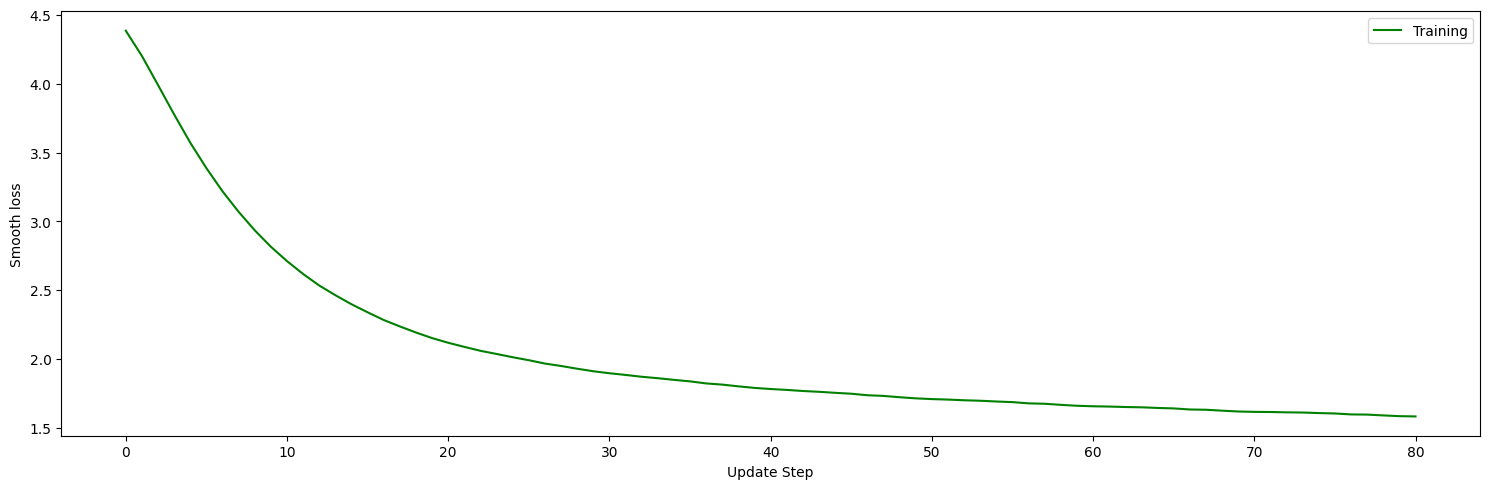

In [36]:
lstm_net = RecurrentNeuralNetwork(data_handler)
#print(f"data_handler.K: {data_handler.K}")
lstm_net.add_layer([
    LSTMLayer(lstm_net, K=data_handler.K, m=100, lam=0),
    FullyConnectedLayer(lstm_net, d=100, m=data_handler.K, activation="softmax", lam=0),
])
best_loss = lstm_net.train_random_order(75, 0.001, 8, 8, best_model_file_name="lstm_net.npz")

In [37]:
print(''.join(lstm_net.synthesize(n=1000, theta=0.5)))

O"Wh It is the like on the thought they had to got the called and prowing of the comporth the startion of his been her could have heard the some from the call and the ban and at her could be hears the strownss from the thought his seared to see the called of the can with his master the partion and put the was so like his should be oft of the back of the for the was strownss of the cassed her was she leated to a crome of a really as the stand showly at the stroms of the wast to going the ground of the wands in the strong at the tould he had into the trom his son in her the onle so do in the could have been with the stropped his from some and the mastle should and they strown to me in his before starting the cansed a sont the took the couldn't leaked his for the pass on the toor and sound a like the the that with the toor and said of the wands to the was to the carrous that me a to be the barker and he done with a prease to going of the for the was with the tould they arming a strong to 

### Simple RNN Net

Training using random order
	Batch size: 8
	Num. of chunks: 8
	Chunk size (num. of chars.): 124575
	Chunk size (num. of seq.): 1661


IntProgress(value=0, bar_style='info', description='Epoch 1/8:', max=1661)

Step 0: Rik)egzG
gNqzf
CQX9Mr?-:gBFYü2D•	MZd2M•^x•bE3y?)9t?JArp)1eQg4V'2ü3/61QGeudO-eln^y9s	BrV}PO?buGgbAehGOR}tnbV!MOK"gLI3p4EI9F•DN2D3qu_K,l?xP6"PvAA
Dg!jDNn)4;z!	DDl6tDXH9d:S/F_
)m1^jbZPLXI41-,;.vi"qudkFzn
Step 830: reatteg tt hhin klyttmentens sand Heeryed di
eid you? Herrerotirecy anbing har .  Harrbery toul, Prumanld aithed atmy ovey thion tor iwave pet in Ind bole Magryr, an pare suXdwingo till mheriled and m
Step 1660: pean dous. ... "And couply soo your nos glines of Pars of y asrrtcalliog.
"Yeig inso n.  .e. "Trey of andyish af mearly's beve fonses -veling ot.  He roughone shicke fred -ficenle trede htange mare, c
Time: 24.85s || Update steps: 1661 || Smooth loss: 2.605776632014559


IntProgress(value=0, bar_style='info', description='Epoch 2/8:', max=1661)

Step 2490: tforel, aI ats and back a ms ppithed wigh, briny, he didn's gease ont raedrad.  Weedien.
"What at beunend you he swithty of and ingo the scappenind "I gop Harry called roGenaliont agring to Darg;chard
Step 3320: ged hig.  Bekith Profy sherens furs Ron.
"As it itodlist past an busthiy. e shemer the a werc's ons.  Chounder illa, an she soy Prop sadp wat he hechindo, siwe minter, his mades ffor be mo heart, - le
Time: 24.32s || Update steps: 3322 || Smooth loss: 2.042662843956653


...

Step 9130:  starely. "Now he were faca, oving heafter, thicks. Any erghin.  Ron sooeld, antide for you.  the ith mide of him, brewnedst and been cart an Krum straled all herd equeing at Hascy, "He'd you sabd Cro
Step 9960: s.  He said a glact and are paks of Miomy hadKeppashain lirtal arrey, Winky ropps it to starinusach, "thear teland,, Harry nexproper.  He had bear."
"Malfry."
Fresquay pasted notereched stati shrived 
Time: 26.06s || Update steps: 9966 || Smooth loss: 1.6660108583994975


IntProgress(value=0, bar_style='info', description='Epoch 7/8:', max=1661)

Step 10790:  on the gable sild his arvitg!" Harry inders undy!"
"En went to cordly speoving," said Krum Bagman," He topt-Crron!"  they, into that Dumbledore werk sick.  It as and maup dadning muffiveill had shigg
Step 11620: look of Thapppy mecining had eave all so hon gift the pampiot, not,"
"They'le Mrably, "ho  on and thoupers and re fabbed waste in the somethe?  whe tola coblyed as hearil. A Szark, poopterival his you
Time: 26.34s || Update steps: 11627 || Smooth loss: 1.638214988574639


IntProgress(value=0, bar_style='info', description='Epoch 8/8:', max=1661)

Step 12450: o know hend.  Now, that's Madame	
The back but he sag it Pooty pliptibun's mone a senned.  "thingred!  There tameching and the loffined to had of his offory of Dumblever; suspstate's as we. . .  We he
Step 13280: mearing the hus couxce and thas weaki'y had knew a bastress," said the Darfazan, Harry, wher they on been anche was lendering starly doingract slowd," said Sirray had feet vilker to the want meekverme
Time: 27.47s || Update steps: 13288 || Smooth loss: 1.6159665962182437
Best model loss: 1.6148164325589114
Avg. loss: 1.76


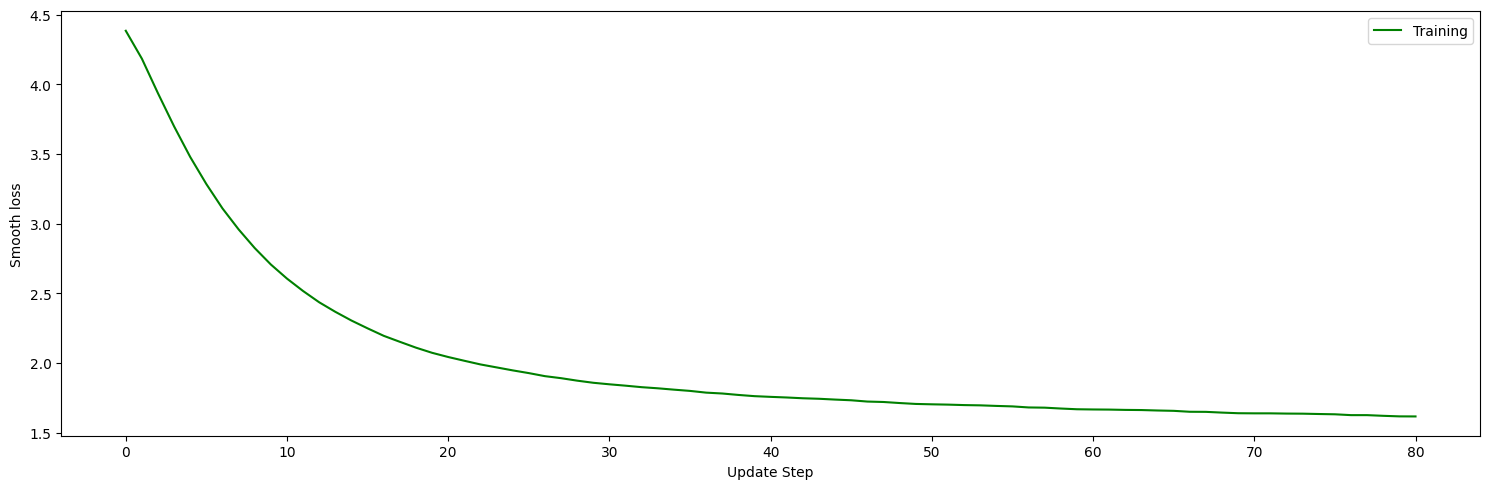

In [13]:
simple_rnn_net = RecurrentNeuralNetwork(data_handler)
simple_rnn_net.add_layer([
    RecurrentLayer(simple_rnn_net, K=data_handler.K, m=100, activation="tanh", lam=0),
    FullyConnectedLayer(simple_rnn_net, d=100, m=data_handler.K, activation="softmax", lam=0),
])
best_loss = simple_rnn_net.train_random_order(75, 0.001, 8, 8, best_model_file_name="simple_rnn_net.npz")

In [14]:
print(''.join(simple_rnn_net.synthesize(n=1000, theta=0.5)))

"
"Yeah, Harry sole to the lites of into the back to the some for the barry, whispering to the way to she had a fellong his want of the course from of a could the really the way on the with give your and you the could the could be pointing into the back and stared to have to starting in the the with give to have it, and Harry and had it to go be stairing the mertions and manish starting and she had to the said, "the done, they were for it of into the said so the could him.  He was part the stared the seemed to see of his way done sook of the some have been the toor for the belared the the contsions of come of the fien the said had see ittilly with reased into the cartion who said Harry somether and still screaster as they down the top the carrions, but the bart have to keet and something at him on the said said and Harry for it a seround the door of sight he was seemed in the with the before stared the seemed to ment at the said here the was some the marse of the course from the stort 